# Logistic Regression — Template Training Notebook (Strategy B)

This notebook is the **template** that every other model notebook should copy. It demonstrates the canonical training/eval pattern using logistic regression as the baseline.

**What this notebook shows:**
1. How to load splits via `_shared/data.py`
2. Three imbalance interventions, fitted as separate configs:
   - **Config 1**: vanilla LogReg, threshold 0.5
   - **Config 2**: `class_weight='balanced'`, threshold 0.5
   - **Config 3**: class-weighted + per-class threshold tuning on val
3. How to pick a winning config on **val** and report final numbers on **test exactly once**
4. How to save a result JSON that downstream comparison notebooks can load

**Why LogReg first**: it's convex (no random seed effects), trains in seconds, and gives a real baseline number for every other model to beat. If your fancy CNN doesn't beat LogReg by a meaningful margin, something is wrong.

**To use this for a different model**: copy this notebook, replace the three `LogisticRegression` lines with your model, and update the `MODEL_NAME` constant. The rest of the pipeline is reusable.

In [1]:
# ============================================================================
# CELL 1 — Setup
# ============================================================================
import sys
from pathlib import Path

# _shared/ lives at project root. Add it to sys.path.
# This notebook is at strategy_A_baseline/notebooks/, so up 2 levels.
_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
import time
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# _shared modules
from data import load_splits, find_root, load_config
from imbalance import compute_class_weights
from eval import (
    predict_with_threshold, tune_thresholds_on_val,
    classification_report, macro_f1, micro_f1,
)
from plot import plot_per_class_f1, plot_confusion_matrices

warnings.filterwarnings('ignore', category=UserWarning)

# --- Configuration --------------------------------------------------------
STRATEGY    = 'B'
MODEL_NAME  = 'logreg'
NOTEBOOK_ID = '03'                            # numeric prefix for save filename
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# --- Paths ---------------------------------------------------------------
ROOT   = find_root()
CONFIG = load_config()
ARTIFACTS = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:      {STRATEGY}")
print(f"Model:         {MODEL_NAME}")
print(f"Root:          {ROOT}")
print(f"Results dir:   {RESULTS_DIR}")

Strategy:      B
Model:         logreg
Root:          /Users/amrabdullah/AI_2026ss/mlpc
Results dir:   /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results


## Cell 2 — Load splits and quick sanity check

`load_splits()` returns a frozen `SplitData` dataclass with all arrays from `splits.npz`. The `.summary()` method is a quick way to confirm you're working with what you think.

In [2]:
# ============================================================================
# CELL 2 — Load data
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

# Quick label sanity check
print(f"\nPositive rate per class (train):")
for c, cls in enumerate(d.class_names):
    rate = d.Y_train[:, c].mean()
    print(f"  {cls:<30s}  {rate*100:>6.2f}%  ({int(d.Y_train[:, c].sum()):>6,d} positives)")

Strategy B
  X_train: (114526, 960)  Y_train: (114526, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes
  train composition: 100,166 real + 14,360 aug = 114,526 (+14.3% of real)

Positive rate per class (train):
  bell_ringing                      3.31%  ( 3,796 positives)
  coffee_machine                    4.57%  ( 5,233 positives)
  cutlery_dishes                    5.32%  ( 6,090 positives)
  door_open_close                   3.58%  ( 4,102 positives)
  footsteps                        10.32%  (11,818 positives)
  keyboard_typing                   8.07%  ( 9,237 positives)
  keychain                          4.08%  ( 4,670 positives)
  light_switch                      0.89%  ( 1,019 positives)
  microwave                         6.07%  ( 6,950 positives)
  phone_ringing                     5.67%  ( 6,488 positives)
  running_water                    11.58%  (13,259 positives)
  toilet_flushing       

## Cell 3 — Define three training configs

All three use the same `OneVsRestClassifier(LogisticRegression(...))` shell. The differences:

| Config | class_weight | threshold | What it tests |
|---|---|---|---|
| 1 | None | 0.5 | naive baseline |
| 2 | `'balanced'` | 0.5 | does loss reweighting help? |
| 3 | `'balanced'` | per-class, tuned on val | does threshold tuning help on top? |

For multi-label `OneVsRestClassifier` fits one binary LR per class. `class_weight='balanced'` is applied independently per class.

> **`solver='lbfgs'`** is sklearn's default for LogReg and works well on 100k × 960 dense data. **`max_iter=1000`** is generous — most classes converge in <200 iters.

In [3]:
# ============================================================================
# CELL 3 — Train Config 1 (vanilla)
# ============================================================================
t0 = time.time()
model_1 = OneVsRestClassifier(
    LogisticRegression(
        solver='lbfgs', max_iter=1000, C=1.0,
        random_state=RANDOM_SEED, n_jobs=1,
    ),
    n_jobs=-1,    # one CPU per class in parallel
)
model_1.fit(d.X_train, d.Y_train)
elapsed_1 = time.time() - t0
print(f"Config 1 (vanilla) trained in {elapsed_1:.1f}s")

# Validation probs (used for all metric computation)
val_probs_1 = model_1.predict_proba(d.X_val)
print(f"Val probs shape: {val_probs_1.shape}")

/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You

Config 1 (vanilla) trained in 419.4s
Val probs shape: (34245, 15)


In [4]:
# ============================================================================
# CELL 4 — Train Config 2 (class-weighted)
# ============================================================================
t0 = time.time()
model_2 = OneVsRestClassifier(
    LogisticRegression(
        solver='lbfgs', max_iter=1000, C=1.0,
        class_weight='balanced',
        random_state=RANDOM_SEED, n_jobs=1,
    ),
    n_jobs=-1,
)
model_2.fit(d.X_train, d.Y_train)
elapsed_2 = time.time() - t0
print(f"Config 2 (class-weighted) trained in {elapsed_2:.1f}s")

val_probs_2 = model_2.predict_proba(d.X_val)

/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/opt/anaconda3/envs/mlpc2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You

Config 2 (class-weighted) trained in 830.5s


## Cell 5 — Evaluate the three configs on val

- **Configs 1 and 2** use a flat threshold of 0.5.
- **Config 3** reuses Config 2's model but with **per-class thresholds tuned on val**. No retraining needed — the model output is the same, only the decision rule changes.

The threshold-tuning sweep is fast (about a second). It picks the F1-optimal threshold per class from `[0.05, 0.95]` in steps of 0.01.

In [5]:
# ============================================================================
# CELL 5 — Evaluate on val
# ============================================================================
class_names = list(d.class_names)

# --- Config 1 — vanilla, threshold 0.5 ---
Y_val_pred_1 = predict_with_threshold(val_probs_1, 0.5)
report_val_1 = classification_report(d.Y_val, Y_val_pred_1, class_names)

# --- Config 2 — class-weighted, threshold 0.5 ---
Y_val_pred_2 = predict_with_threshold(val_probs_2, 0.5)
report_val_2 = classification_report(d.Y_val, Y_val_pred_2, class_names)

# --- Config 3 — class-weighted + per-class thresholds tuned on val ---
threshold_df = tune_thresholds_on_val(val_probs_2, d.Y_val, class_names=class_names)
thresholds_3 = threshold_df['threshold'].loc[class_names].values
Y_val_pred_3 = predict_with_threshold(val_probs_2, thresholds_3)
report_val_3 = classification_report(d.Y_val, Y_val_pred_3, class_names)

# --- Side-by-side comparison (macro/micro F1) ---
print(f"=== VAL RESULTS ===\n")
print(f"  {'config':<35s}  {'macro_f1':>9s}  {'micro_f1':>9s}")
for name, rep in [
    ("1 - vanilla (th=0.5)", report_val_1),
    ("2 - class-weighted (th=0.5)", report_val_2),
    ("3 - class-weighted + tuned thr", report_val_3),
]:
    m = rep.loc['macro avg', 'f1']
    u = rep.loc['micro avg', 'f1']
    print(f"  {name:<35s}  {m:>9.4f}  {u:>9.4f}")

print(f"\n=== Tuned thresholds (Config 3) ===")
print(threshold_df[['threshold', 'val_f1', 'val_support']].to_string())

=== VAL RESULTS ===

  config                                macro_f1   micro_f1
  1 - vanilla (th=0.5)                    0.4474     0.5635
  2 - class-weighted (th=0.5)             0.3825     0.4367
  3 - class-weighted + tuned thr          0.4778     0.5589

=== Tuned thresholds (Config 3) ===
                            threshold  val_f1  val_support
class                                                     
bell_ringing                     0.91  0.4280          480
coffee_machine                   0.95  0.5161         1073
cutlery_dishes                   0.85  0.4970         1828
door_open_close                  0.88  0.3168         1177
footsteps                        0.75  0.4814         4033
keyboard_typing                  0.86  0.7088         3107
keychain                         0.93  0.5609         1553
light_switch                     0.94  0.1605          140
microwave                        0.90  0.5734         2253
phone_ringing                    0.88  0.6585        

## Cell 6 — Per-class comparison

The macro F1 numbers above hide where the gains come from. Almost always with class imbalance: the rare classes are where reweighting + threshold tuning pay off, while common classes might tick down slightly (more false positives from the lower thresholds).

In [6]:
# ============================================================================
# CELL 6 — Per-class F1 comparison across configs
# ============================================================================
comparison = pd.DataFrame({
    'config_1_vanilla':       report_val_1.loc[class_names, 'f1'],
    'config_2_weighted':      report_val_2.loc[class_names, 'f1'],
    'config_3_weighted_tuned': report_val_3.loc[class_names, 'f1'],
    'support':                report_val_1.loc[class_names, 'support'],
})
comparison['gain_2_over_1'] = (comparison['config_2_weighted']      - comparison['config_1_vanilla']).round(4)
comparison['gain_3_over_2'] = (comparison['config_3_weighted_tuned'] - comparison['config_2_weighted']).round(4)
comparison = comparison.sort_values('support', ascending=True)   # rare → common

print("=== Per-class F1 by config (sorted rare → common) ===\n")
print(comparison.to_string())

=== Per-class F1 by config (sorted rare → common) ===

                            config_1_vanilla  config_2_weighted  config_3_weighted_tuned  support  gain_2_over_1  gain_3_over_2
class                                                                                                                          
light_switch                          0.0994             0.1280                   0.1605    140.0         0.0286         0.0325
window_open_close                     0.0968             0.1440                   0.2075    421.0         0.0472         0.0635
bell_ringing                          0.3853             0.3651                   0.4280    480.0        -0.0202         0.0629
wardrobe_drawer_open_close            0.1248             0.1549                   0.2161    613.0         0.0301         0.0612
toilet_flushing                       0.5353             0.3539                   0.4896    967.0        -0.1814         0.1357
coffee_machine                        0.5506     

## Cell 7 — Pick winning config and run final test eval

**The discipline that matters:** test gets touched **once**. We pick the winning config based on **val macro F1**, then evaluate that one config on test and report the final number. Running test on multiple configs and picking the best one is leakage — it turns test into a second validation set.

In [7]:
# ============================================================================
# CELL 7 — Pick winner on val, then evaluate on test
# ============================================================================
val_scores = {
    1: report_val_1.loc['macro avg', 'f1'],
    2: report_val_2.loc['macro avg', 'f1'],
    3: report_val_3.loc['macro avg', 'f1'],
}
winner = max(val_scores, key=val_scores.get)
print(f"Winner on val: Config {winner} (macro F1 = {val_scores[winner]:.4f})\n")

# Recover the winning model and thresholds
if winner == 1:
    winning_model, winning_thresholds = model_1, np.full(d.C, 0.5)
elif winner == 2:
    winning_model, winning_thresholds = model_2, np.full(d.C, 0.5)
else:
    winning_model, winning_thresholds = model_2, thresholds_3

# Final test eval — only run once
test_probs = winning_model.predict_proba(d.X_test)
Y_test_pred = predict_with_threshold(test_probs, winning_thresholds)
report_test = classification_report(d.Y_test, Y_test_pred, class_names)

print(f"=== TEST RESULTS (Config {winner}) ===")
print(report_test.round(4).to_string())

Winner on val: Config 3 (macro F1 = 0.4778)

=== TEST RESULTS (Config 3) ===
                            precision  recall      f1  support
class                                                         
bell_ringing                   0.3134  0.5652  0.4032    483.0
coffee_machine                 0.5832  0.4223  0.4899   1236.0
cutlery_dishes                 0.4844  0.6284  0.5470   2045.0
door_open_close                0.3041  0.4253  0.3546   1077.0
footsteps                      0.4457  0.5134  0.4772   4256.0
keyboard_typing                0.7040  0.6295  0.6647   3333.0
keychain                       0.5280  0.5237  0.5259   1474.0
light_switch                   0.0476  0.1250  0.0690     88.0
microwave                      0.6639  0.5843  0.6216   2579.0
phone_ringing                  0.6359  0.6864  0.6602   2076.0
running_water                  0.6615  0.8026  0.7253   4190.0
toilet_flushing                0.4990  0.4749  0.4867   1076.0
vacuum_cleaner                 0.6010  0.

## Cell 8 — Plots: per-class F1 + confusion matrices on test

These figures go into the report. The per-class F1 plot in particular is the headline figure for any individual model — it shows which classes the model handles well and which need work.

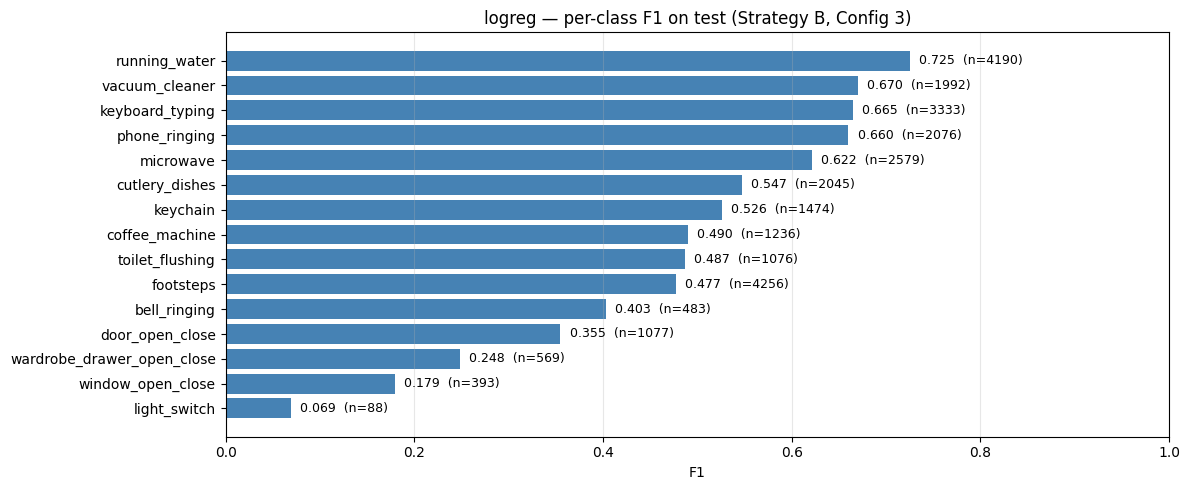

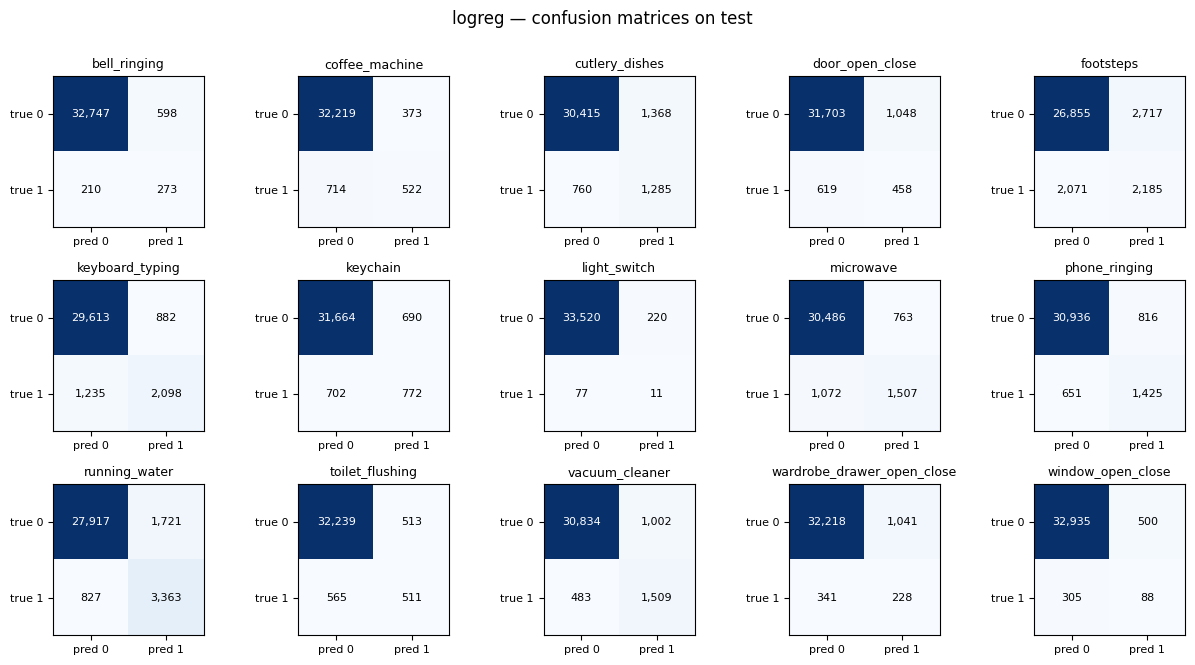

In [8]:
# ============================================================================
# CELL 8 — Plots
# ============================================================================
fig, ax = plot_per_class_f1(
    report_test, class_names=class_names,
    title=f"{MODEL_NAME} — per-class F1 on test (Strategy {STRATEGY}, Config {winner})",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png", dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plot_confusion_matrices(
    d.Y_test, Y_test_pred, class_names=class_names,
    title=f"{MODEL_NAME} — confusion matrices on test",
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_confusion.png", dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — Save results JSON

Result file convention: `strategy_<x>_baseline/artifacts/results/<id>_<model>.json`. Downstream comparison notebooks (the one that builds the report's "all models on all strategies" table) loads these.

Saved fields:
- `meta`: strategy, model, timestamp, training times
- `config`: which intervention won, the thresholds, hyperparameters
- `val_report`, `test_report`: the per-class tables
- `headline`: macro/micro F1 on test — the single number to put in the comparison table

In [9]:
# ============================================================================
# CELL 9 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':       STRATEGY,
        'model':          MODEL_NAME,
        'notebook_id':    NOTEBOOK_ID,
        'timestamp':      datetime.now().isoformat(timespec='seconds'),
        'random_seed':    RANDOM_SEED,
        'training_seconds': {
            'config_1_vanilla':  round(elapsed_1, 2),
            'config_2_weighted': round(elapsed_2, 2),
        },
        'n_train': int(d.N_train),
        'n_val':   int(d.N_val),
        'n_test':  int(d.N_test),
    },
    'winning_config': {
        'config_id':  int(winner),
        'description': [
            "1 - vanilla LogReg (threshold 0.5)",
            "2 - class_weight='balanced' (threshold 0.5)",
            "3 - class_weight='balanced' + per-class thresholds tuned on val",
        ][winner - 1],
        'thresholds': [float(t) for t in winning_thresholds],
        'hyperparameters': {
            'solver':       'lbfgs',
            'max_iter':     1000,
            'C':            1.0,
            'class_weight': 'balanced' if winner >= 2 else None,
        },
    },
    'val_scores_macro_f1': {f'config_{k}': float(v) for k, v in val_scores.items()},
    'val_report':   df_to_jsonable(report_val_3 if winner == 3 else (report_val_2 if winner == 2 else report_val_1)),
    'test_report':  df_to_jsonable(report_test),
    'headline_test': {
        'macro_f1': float(report_test.loc['macro avg', 'f1']),
        'micro_f1': float(report_test.loc['micro avg', 'f1']),
        'weighted_f1': float(report_test.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE ===")
print(f"  Strategy {STRATEGY} / {MODEL_NAME} / Config {winner}")
print(f"  Test macro F1: {results['headline_test']['macro_f1']:.4f}")
print(f"  Test micro F1: {results['headline_test']['micro_f1']:.4f}")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_B_with_aug/artifacts/results/03_logreg.json

=== HEADLINE ===
  Strategy B / logreg / Config 3
  Test macro F1: 0.4749
  Test micro F1: 0.5661


## Done.

**What got produced:**
- `results/03_logreg.json` — the headline number + full per-class report (for the comparison table later).
- `results/03_logreg_per_class_f1.png` — per-class F1 bar plot.
- `results/03_logreg_confusion.png` — 15 per-class confusion matrices.

**To run this same pipeline with a different model**, copy this notebook and:
1. Change `MODEL_NAME` and `NOTEBOOK_ID` in Cell 1.
2. Replace the `LogisticRegression(...)` in Cells 3 and 4 with your model (`RandomForestClassifier`, `XGBClassifier`, etc.).
3. If the model doesn't have a `predict_proba`, replace it with `decision_function` and sigmoid-normalize, or use the model's analog.
4. Run the whole notebook.

**To run the same on Strategy B**

In [10]:
# Trivial baselines for comparison anchor
from sklearn.dummy import DummyClassifier
import numpy as np

# Random guess that respects per-class frequency
dummy = DummyClassifier(strategy='stratified', random_state=42)
# (For multi-label, fit one per class via OvR — or just compute by hand:)

# Even simpler: predict positive at the per-class base rate
np.random.seed(42)
priors = d.Y_train.mean(axis=0)                         # per-class positive rate
Y_test_random = (np.random.rand(*d.Y_test.shape) < priors[None, :]).astype(np.int8)
report_random = classification_report(d.Y_test, Y_test_random, class_names)
print(report_random.round(4).to_string())

                            precision  recall      f1  support
class                                                         
bell_ringing                   0.0205  0.0497  0.0290    483.0
coffee_machine                 0.0402  0.0494  0.0443   1236.0
cutlery_dishes                 0.0706  0.0626  0.0663   2045.0
door_open_close                0.0391  0.0446  0.0416   1077.0
footsteps                      0.1298  0.1062  0.1168   4256.0
keyboard_typing                0.0941  0.0780  0.0853   3333.0
keychain                       0.0429  0.0407  0.0418   1474.0
light_switch                   0.0000  0.0000  0.0000     88.0
microwave                      0.0767  0.0589  0.0666   2579.0
phone_ringing                  0.0601  0.0564  0.0582   2076.0
running_water                  0.1205  0.1136  0.1170   4190.0
toilet_flushing                0.0345  0.0455  0.0392   1076.0
vacuum_cleaner                 0.0525  0.0552  0.0538   1992.0
wardrobe_drawer_open_close     0.0141  0.0299  0.0192  